# Simple linear regression in Python

In this notebook we fit a simple linear regression that predicts **Salary** from **YearsExperience**. The steps are:

1. Load the packages and the data
2. Clean the data and visualize it
3. Fit the regression with `statsmodels`
4. Add the fitted line to the plot
5. Use the model to make a prediction

----

## Load packages

- `pandas` holds the data in a data frame.
- `matplotlib` and `seaborn` draw the graphs.
- `statsmodels` fits the linear model using an R-style formula.

In [1]:
# load-packages
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

## Load the data

Read `Salary_dataset.csv` into a data frame. The file must be in the same folder as this notebook (or adjust the path). Then look at the first few rows.

In [3]:
# load-data
df = pd.read_csv("Salary_dataset.csv")

# look at the first few rows
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


## Clean the data

The first column, `Unnamed: 0`, is just a row number left over from how the file was saved, so we drop it. We then print the head again to confirm that the correct column was removed.

In [4]:
# drop-index-column
df = df.drop(columns=df.columns[0])

# confirm that we removed the correct column
df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


## Visualize the data

Before fitting a model, plot Salary against YearsExperience to see whether a straight line is a reasonable description of the relationship.

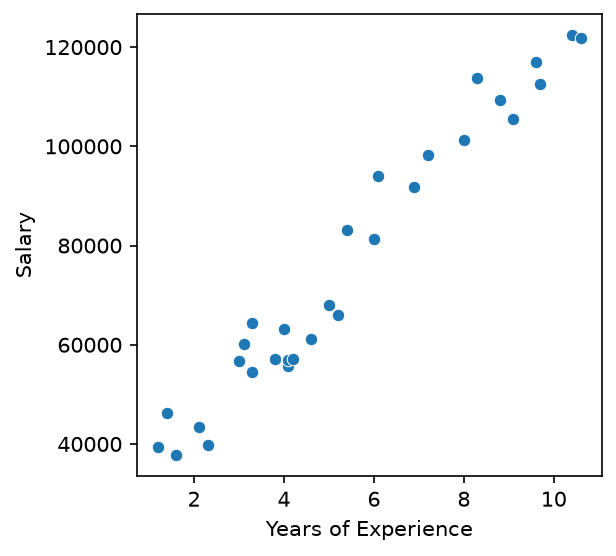

In [5]:
# plot-raw-data
fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(
    data=df,
    x="YearsExperience",
    y="Salary",
    ax=ax,
)
ax.set_xlabel("Years of Experience")
ax.set_ylabel("Salary")
plt.show()

# To save a PDF of the graph with a transparent background, uncomment:
# fig.savefig("salary_data_plot_python.pdf", transparent=True, bbox_inches="tight")

## Fit the linear regression

`smf.ols("Salary ~ YearsExperience", ...)` specifies an ordinary least squares model with Salary as the response and YearsExperience as the predictor. An intercept is included automatically. `.fit()` estimates the coefficients, and `.summary()` reports the coefficients, standard errors, p-values, R-squared, and other diagnostics.

In [6]:
# fit-model
model = smf.ols("Salary ~ YearsExperience", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     622.5
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.14e-20
Time:                        22:55:52   Log-Likelihood:                -301.44
No. Observations:                  30   AIC:                             606.9
Df Residuals:                      28   BIC:                             609.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        2.485e+04   2306.654     

## Plot the fitted line

Redraw the scatter plot and overlay the regression line. `sns.regplot` fits its own least squares line, which matches the `statsmodels` fit for this simple model. We set `scatter=False` so the points are not drawn twice, and `ci=None` to hide the confidence band.

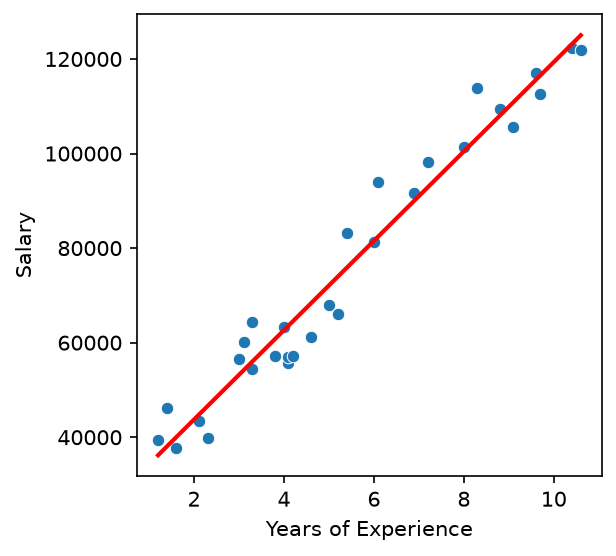

In [7]:
# plot-fitted-line
fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(
    data=df,
    x="YearsExperience",
    y="Salary",
    ax=ax,
)
sns.regplot(
    data=df,
    x="YearsExperience",
    y="Salary",
    scatter=False,
    ci=None,
    color="red",
    line_kws={"linewidth": 2},
    ax=ax,
)
ax.set_xlabel("Years of Experience")
ax.set_ylabel("Salary")
plt.show()

# To save a PDF of the graph with a transparent background, uncomment:
# fig.savefig("linear_regression_python.pdf", transparent=True, bbox_inches="tight")

## Make a prediction

A linear model should only be used to predict within (or very near) the range of the data it was fit on. Extrapolating far outside that range is unreliable. So first we summarize the range of `YearsExperience`.

In [8]:
# summarize-input-range
df["YearsExperience"].describe()

count    30.000000
mean      5.413333
std       2.837888
min       1.200000
25%       3.300000
50%       4.800000
75%       7.800000
max      10.600000
Name: YearsExperience, dtype: float64

Now predict the salary for someone with 6.3 years of experience. The new input must be a data frame with the same column name used in the model formula.

In [9]:
# predict-salary
new_data = pd.DataFrame({"YearsExperience": [6.3]})
model.predict(new_data)

0    84382.966592
dtype: float64